In [1]:
import pandas as pd
from scipy import stats
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from matplotlib import pyplot as plt
from mlxtend.plotting import plot_confusion_matrix

import tensorflow as tf
from keras.models import Sequential, load_model
from keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.layers import TimeDistributed, Dense, BatchNormalization, LSTM, Dropout, Bidirectional, Flatten, Conv1D, MaxPool1D, GlobalAveragePooling1D, Reshape, Conv2D, MaxPool2D
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report

import seaborn as sns

In [2]:
#read dataset into a dataframe
file_path = "anxiety_dataset.csv"

df = pd.read_csv(file_path)


In [3]:
df

,Activity,Ax_p,Ax_w,Ay_p,Ay_w,Az_p,Az_w,GPS1_p,GPS2_p,Gx_p,...,Mx_w,My_p,My_w,Mz_p,Mz_w,PocketDev,Time_p,Time_w,User,WristDev
0,knuckles_cracking,-1.127655,0.77,-2.090134,-0.45,9.476257,-0.34,0.0,0.0,-0.001160,...,-100.98,-45.750427,-58.96,-163.049320,-22.21,S8,1.557220e+12,3392.0,3,SF1
1,knuckles_cracking,-1.127655,0.76,-2.090134,-0.44,9.476257,-0.36,0.0,0.0,-0.003830,...,-100.98,-46.949768,-58.96,-162.150570,-22.21,S8,1.557220e+12,3401.0,3,SF1
2,knuckles_cracking,-1.120483,0.74,-2.075775,-0.43,9.519363,-0.35,0.0,0.0,-0.005508,...,-100.98,-46.800232,-58.96,-161.549380,-22.21,S8,1.557220e+12,3420.0,3,SF1
3,knuckles_cracking,-1.113296,0.74,-2.061401,-0.40,9.533722,-0.38,0.0,0.0,-0.005493,...,-100.98,-46.949768,-58.96,-162.150570,-22.21,S8,1.557220e+12,3440.0,3,SF1
4,knuckles_cracking,-1.120483,0.74,-2.047043,-0.43,9.526535,-0.39,0.0,0.0,-0.005798,...,-100.68,-46.800232,-59.41,-164.549260,-19.20,S8,1.557220e+12,3460.0,3,SF1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
709577,hand_scratching,0.086960,0.23,0.784858,0.22,9.869260,-0.75,0.0,0.0,-0.000206,...,-66.47,-33.377078,-11.10,-21.132091,-43.06,SJ7,1.570370e+12,125969.0,6,SF1
709578,hand_scratching,0.086960,0.18,0.784858,0.42,9.869260,-0.72,0.0,0.0,-0.000206,...,-66.47,-33.377078,-11.10,-21.132091,-43.06,SJ7,1.570370e+12,125989.0,6,SF1
709579,hand_scratching,0.086960,0.13,0.784858,0.43,9.869260,-0.76,0.0,0.0,-0.000206,...,-66.47,-33.377078,-11.10,-21.132091,-43.06,SJ7,1.570370e+12,126010.0,6,SF1
709580,hand_scratching,0.086960,0.12,0.784858,0.32,9.869260,-0.78,0.0,0.0,-0.000206,...,-66.47,-33.377078,-11.10,-21.132091,-43.06,SJ7,1.570370e+12,126030.0,6,SF1


In [4]:
df.apply(lambda s: pd.to_numeric(s, errors='coerce').notnull().all())

Activity     False
Ax_p          True
Ax_w          True
Ay_p          True
Ay_w          True
Az_p          True
Az_w          True
GPS1_p       False
GPS2_p       False
Gx_p          True
Gx_w          True
Gy_p          True
Gy_w          True
Gz_p          True
Gz_w          True
Mx_p          True
Mx_w          True
My_p          True
My_w          True
Mz_p          True
Mz_w          True
PocketDev    False
Time_p        True
Time_w        True
User          True
WristDev     False
dtype: bool

## Separate wrist data

In [4]:
df_w = df.drop(["Ax_p", "Ay_p", "Az_p", "GPS1_p","GPS2_p", "Gx_p", "Gy_p", "Gz_p",  "Mx_p", "My_p", "Mz_p","PocketDev", "Time_p","WristDev" ], axis =1)
df_w #dataset for waist data

,Activity,Ax_w,Ay_w,Az_w,Gx_w,Gy_w,Gz_w,Mx_w,My_w,Mz_w,Time_w,User
0,knuckles_cracking,0.77,-0.45,-0.34,-4.70,-0.98,2.44,-100.98,-58.96,-22.21,3392.0,3
1,knuckles_cracking,0.76,-0.44,-0.36,-8.48,-4.39,5.24,-100.98,-58.96,-22.21,3401.0,3
2,knuckles_cracking,0.74,-0.43,-0.35,-15.49,-9.15,6.59,-100.98,-58.96,-22.21,3420.0,3
3,knuckles_cracking,0.74,-0.40,-0.38,-20.12,-14.27,6.71,-100.98,-58.96,-22.21,3440.0,3
4,knuckles_cracking,0.74,-0.43,-0.39,-14.02,-19.94,7.13,-100.68,-59.41,-19.20,3460.0,3
...,...,...,...,...,...,...,...,...,...,...,...,...
709577,hand_scratching,0.23,0.22,-0.75,-163.54,-3.23,37.87,-66.47,-11.10,-43.06,125969.0,6
709578,hand_scratching,0.18,0.42,-0.72,-231.59,-17.87,31.16,-66.47,-11.10,-43.06,125989.0,6
709579,hand_scratching,0.13,0.43,-0.76,-248.54,-24.94,13.60,-66.47,-11.10,-43.06,126010.0,6
709580,hand_scratching,0.12,0.32,-0.78,-262.13,-27.56,-2.26,-66.47,-11.10,-43.06,126030.0,6


In [5]:
df_acc_gyro = df_w.drop(["Mx_w", "My_w", "Mz_w","Time_w"], axis = 1)

In [6]:
df_acc_gyro #dataset with accelerometer and gyroscope data FROM WRIST SENSOR

,Activity,Ax_w,Ay_w,Az_w,Gx_w,Gy_w,Gz_w,User
0,knuckles_cracking,0.77,-0.45,-0.34,-4.70,-0.98,2.44,3
1,knuckles_cracking,0.76,-0.44,-0.36,-8.48,-4.39,5.24,3
2,knuckles_cracking,0.74,-0.43,-0.35,-15.49,-9.15,6.59,3
3,knuckles_cracking,0.74,-0.40,-0.38,-20.12,-14.27,6.71,3
4,knuckles_cracking,0.74,-0.43,-0.39,-14.02,-19.94,7.13,3
...,...,...,...,...,...,...,...,...
709577,hand_scratching,0.23,0.22,-0.75,-163.54,-3.23,37.87,6
709578,hand_scratching,0.18,0.42,-0.72,-231.59,-17.87,31.16,6
709579,hand_scratching,0.13,0.43,-0.76,-248.54,-24.94,13.60,6
709580,hand_scratching,0.12,0.32,-0.78,-262.13,-27.56,-2.26,6


In [7]:
df_acc_gyro.shape
#df_w.shape
#df.shape

(709582, 8)

## Check if data is balanced

<Axes: xlabel='Activity', ylabel='count'>

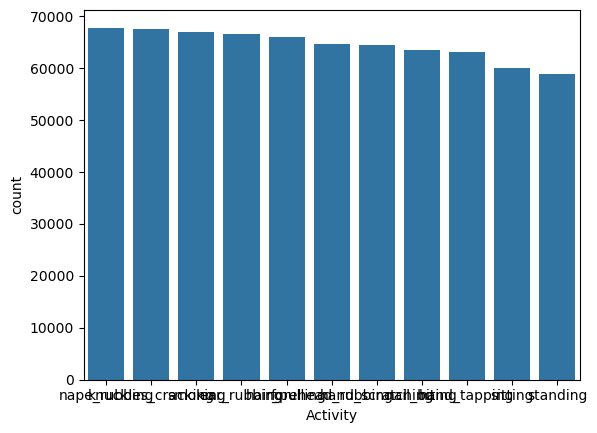

In [8]:
#check the distribution of the activities
sns.countplot(x='Activity', data = df, order=df.Activity.value_counts().index)

<Axes: xlabel='User', ylabel='count'>

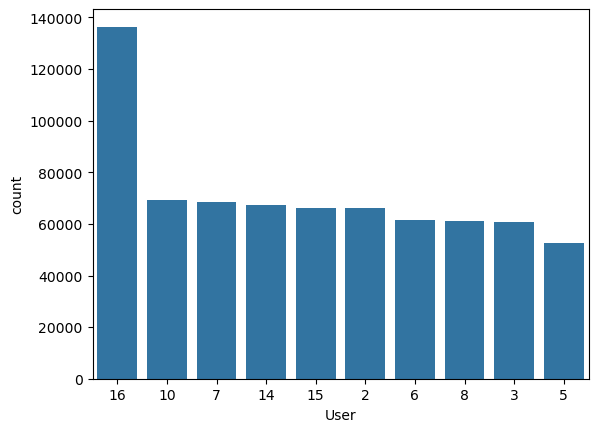

In [12]:
#Check the distribution for users
sns.countplot(x='User', data = df, order=df.User.value_counts().index)

In [13]:
def plot_activity(activity,df,axes):
    """
    Function that plots the x,y and z signals of a single activity 
    """
    data =df[df['Activity']==activity][axes][:200]
    axis = data.plot(subplots=True, figsize=(16,12), title=activity)
    for ax in axis:
        ax.legend(loc='lower left', bbox_to_anchor=(1.0, 0.5))

In [14]:
#lists containing the axes for a, g and m for pocket and wrist data
aw_axis = ["Ax_w", "Ay_w", "Az_w"]
gw_axis = ["Gx_w", "Gy_w", "Gz_w"]
mw_axis = ["Mx_w", "My_w", "Mz_w"]
ap_axis = ["Ax_p", "Ay_p", "Az_p"]
gp_axis = ["Gx_p", "Gy_p", "Gz_p"]
mp_axis = ["Mx_p", "My_p", "Mz_p"]

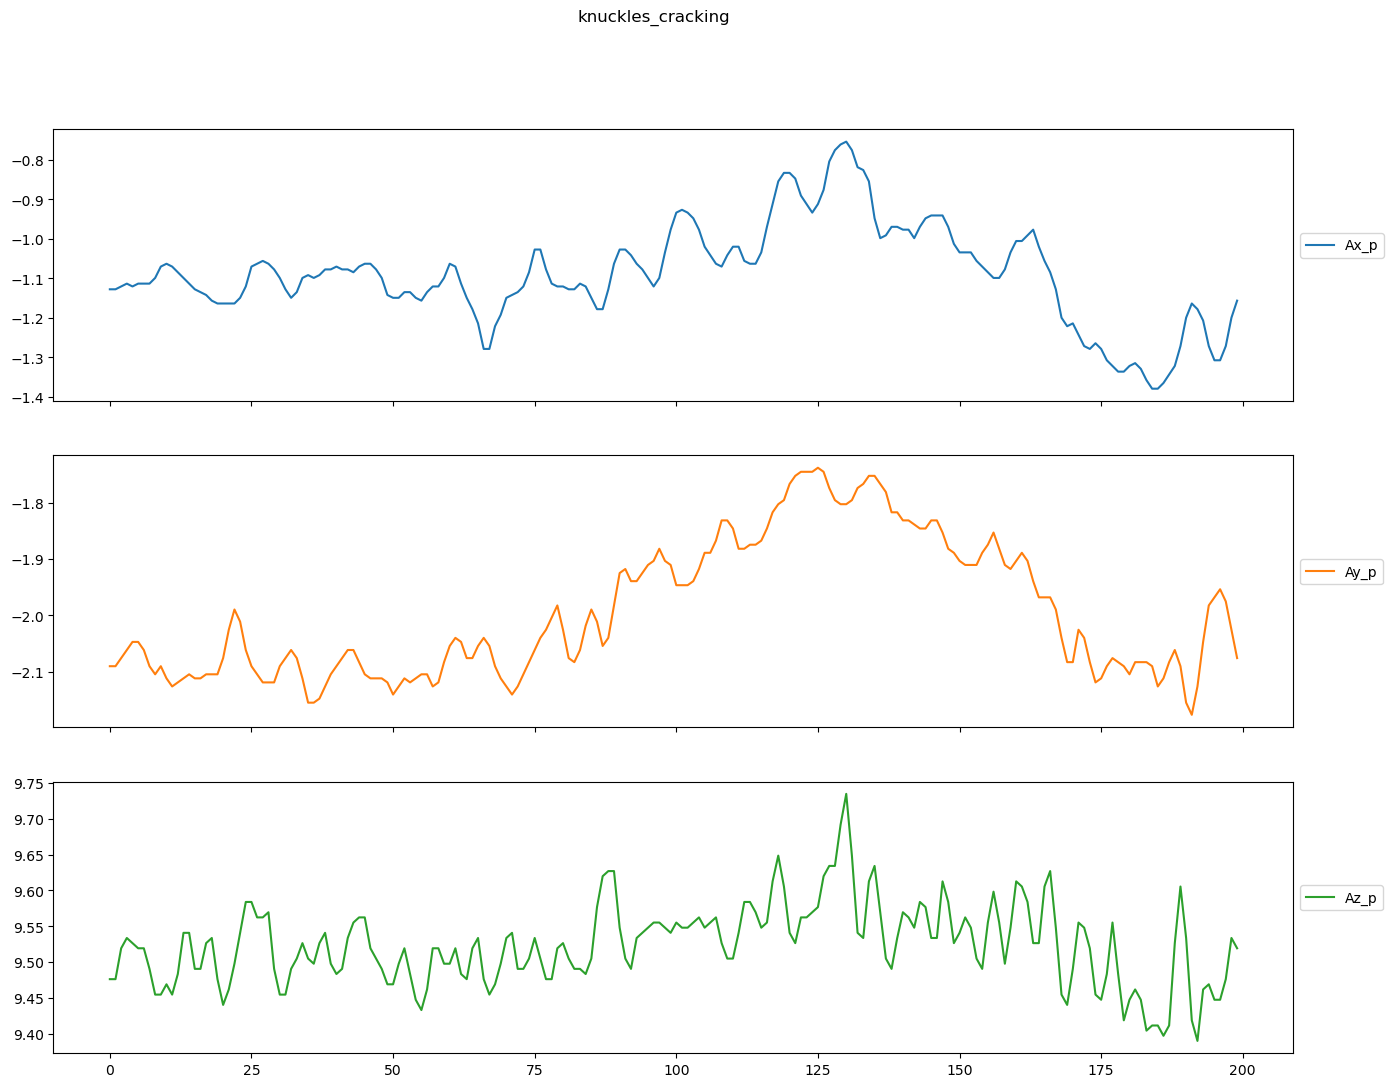

In [15]:
plot_activity("knuckles_cracking",df,ap_axis)

In [16]:
df['Activity'].value_counts()

Activity
nape_rubbing         67859
knuckles_cracking    67498
smoking              66937
ear_rubbing          66599
hair_pulling         65973
forehead_rubbing     64604
hand_scratching      64490
nail_biting          63457
hand_tapping         63220
sitting              59996
standing             58949
Name: count, dtype: int64

In [18]:
srate = 50 #sample rate

## Encode Data

In [8]:
#encode data
label = LabelEncoder()
df_acc_gyro['label'] = label.fit_transform(df_acc_gyro['Activity'])
df_acc_gyro.head()

,Activity,Ax_w,Ay_w,Az_w,Gx_w,Gy_w,Gz_w,User,label
0,knuckles_cracking,0.77,-0.45,-0.34,-4.70,-0.98,2.44,3,5
1,knuckles_cracking,0.76,-0.44,-0.36,-8.48,-4.39,5.24,3,5
2,knuckles_cracking,0.74,-0.43,-0.35,-15.49,-9.15,6.59,3,5
3,knuckles_cracking,0.74,-0.40,-0.38,-20.12,-14.27,6.71,3,5
4,knuckles_cracking,0.74,-0.43,-0.39,-14.02,-19.94,7.13,3,5


In [9]:
label.classes_

array(['ear_rubbing', 'forehead_rubbing', 'hair_pulling',
       'hand_scratching', 'hand_tapping', 'knuckles_cracking',
       'nail_biting', 'nape_rubbing', 'sitting', 'smoking', 'standing'],
      dtype=object)

## Standardize Data

In [10]:
#standardize data
columns = ["Ax_w", "Ay_w", "Az_w","Gx_w", "Gy_w", "Gz_w"]
x=df_acc_gyro[columns]
scaler = StandardScaler()
x = scaler.fit_transform(x)
scaled_x = pd.DataFrame(data = x, columns = columns)

y = df_acc_gyro['label']

scaled_x['label'] = y.values

scaled_x

,Ax_w,Ay_w,Az_w,Gx_w,Gy_w,Gz_w,label
0,0.936100,-1.018411,0.301650,-0.078197,-0.114346,0.112631,5
1,0.918868,-0.998366,0.250270,-0.156196,-0.258315,0.246124,5
2,0.884404,-0.978321,0.275960,-0.300845,-0.459281,0.310486,5
3,0.884404,-0.918187,0.198890,-0.396383,-0.675446,0.316207,5
4,0.884404,-0.978321,0.173200,-0.270512,-0.914831,0.336231,5
...,...,...,...,...,...,...,...
709577,0.005570,0.324587,-0.751639,-3.355805,-0.209340,1.801788,3
709578,-0.080590,0.725482,-0.674569,-4.759993,-0.827437,1.481883,3
709579,-0.166750,0.745527,-0.777329,-5.109750,-1.125930,0.644694,3
709580,-0.183982,0.525034,-0.828709,-5.390175,-1.236546,-0.111446,3


In [5]:
#window frame
window_size = 200 #4 seconds
slide_size = 100 #50 percent overlap

In [4]:
def get_window(df, window_size, slide_size):
    '''
    Function that creates a window frame for the dataset
    
    Parameters:
    df: dataframe
    window_size: int, size of the window
    slide_size: int, size of the overlap
    
    Returns:
    windows: array, array of windows
    labels: array, array of labels
    '''
    N_features = 6
    
    windows = []
    labels = []
    for i in range(0, len(df)-window_size, slide_size):
        Ax_w = df['Ax_w'].values[i: i + window_size]
        Ay_w = df['Ay_w'].values[i: i + window_size]
        Az_w = df['Az_w'].values[i: i + window_size]
        Gx_w = df['Gx_w'].values[i: i + window_size]
        Gy_w = df['Gy_w'].values[i: i + window_size]
        Gz_w = df['Gz_w'].values[i: i + window_size]
        
        label = stats.mode(df['label'][i:i+window_size])[0]
        windows.append([Ax_w ,Ay_w ,Az_w,Gx_w ,Gy_w ,Gz_w ])
        labels.append(label)
        
    windows = np.asarray(windows).reshape(-1, window_size, N_features)
    labels = np.asarray(labels)
    
    return windows, labels

In [13]:
x, y = get_window(scaled_x, window_size, slide_size)
x.shape, y.shape

((7094, 200, 6), (7094,))

In [14]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3, random_state =0, stratify=y)
x_train.shape, x_test.shape

((4965, 200, 6), (2129, 200, 6))

In [18]:
#Reshape
x_train = x_train.reshape(4965, 200, 6,1)
x_test =x_test.reshape(2129, 200, 6, 1)

## Model


In [19]:
input_shape=x_train[0].shape

In [40]:
x_train[0].shape

(200, 6)

In [16]:
model_cnnbilstm = Sequential([
    Conv1D(16,kernel_size= 2, activation = 'relu', input_shape = x_train[0].shape),
    BatchNormalization(),
    Dropout(0.1),

    Conv1D(32,kernel_size=2, activation = 'relu'),
    BatchNormalization(),
    Dropout(0.2),

    Bidirectional(LSTM(64, return_sequences = True)),
    BatchNormalization(),
    Dropout(0.2),

    Bidirectional(LSTM(32, return_sequences = True)),
    BatchNormalization(),
    Dropout(0.2),

    Flatten(),

    Dense(32, activation = 'relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(11, activation = 'softmax'),
    
    ]
)

model_cnnbilstm.summary()

c:\Users\Ugonna Oleh\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 199, 16)        │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 199, 16)        │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 199, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 198, 32)        │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 198, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 198, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 198, 128)       │        49,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 198, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 198, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 198, 64)        │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 198, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 198, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 12672)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │       405,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 11)             │           363 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 499,131 (1.90 MB)

 Trainable params: 498,587 (1.90 MB)

 Non-trainable params: 544 (2.12 KB)

In [18]:
#define some variables to allow the training stop early if the accuracy is not increasing and to also save the final model

# stop training when val_accuracy has stopped improving
early_stop = EarlyStopping(monitor='val_accuracy', patience=5, verbose=1, mode='max')

# callback to save the Keras model and (best) weights obtained on an epoch basis.
checkpoint = ModelCheckpoint('cnn_bilstm.keras',
                                         monitor='val_accuracy',
                                         verbose=1,
                                         save_weights_only=False,
                                         save_best_only=True,
                                         mode='max',
                                         save_freq='epoch')

In [19]:
model_cnnbilstm.compile(optimizer = Adam(learning_rate=0.001), loss ='sparse_categorical_crossentropy', metrics = ['accuracy'])

### Training

In [20]:
history = model_cnnbilstm.fit(x_train, y_train, epochs = 50, validation_data =(x_test,y_test), callbacks=[early_stop, checkpoint], verbose=1)

Epoch 1/50
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - accuracy: 0.4473 - loss: 1.7507
Epoch 1: val_accuracy improved from -inf to 0.42179, saving model to cnn_bilstm.keras
156/156 ━━━━━━━━━━━━━━━━━━━━ 39s 195ms/step - accuracy: 0.4478 - loss: 1.7489 - val_accuracy: 0.4218 - val_loss: 1.4515
Epoch 2/50
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.6398 - loss: 1.0805
Epoch 2: val_accuracy improved from 0.42179 to 0.73791, saving model to cnn_bilstm.keras
156/156 ━━━━━━━━━━━━━━━━━━━━ 23s 146ms/step - accuracy: 0.6399 - loss: 1.0802 - val_accuracy: 0.7379 - val_loss: 0.8075
Epoch 3/50
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step - accuracy: 0.6937 - loss: 0.9214
Epoch 3: val_accuracy improved from 0.73791 to 0.78159, saving model to cnn_bilstm.keras
156/156 ━━━━━━━━━━━━━━━━━━━━ 28s 182ms/step - accuracy: 0.6937 - loss: 0.9213 - val_accuracy: 0.7816 - val_loss: 0.6116
Epoch 4/50
156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - accuracy: 0.7193 - loss: 0.8646
Epoch 4: val_accuracy di

In [21]:
model_cnnbilstm.evaluate(x_test, y_test)

67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.8911 - loss: 0.3757


[0.35319024324417114, 0.895725667476654]

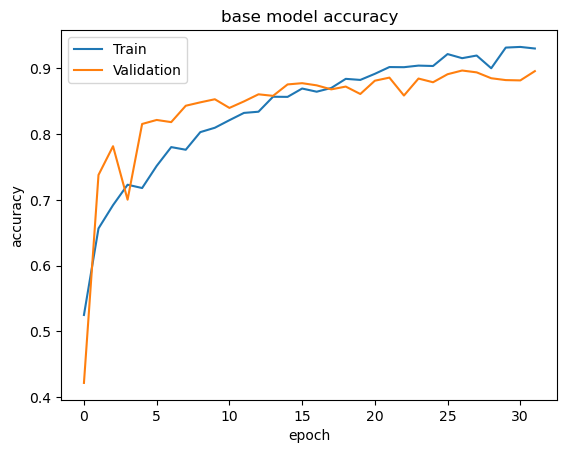

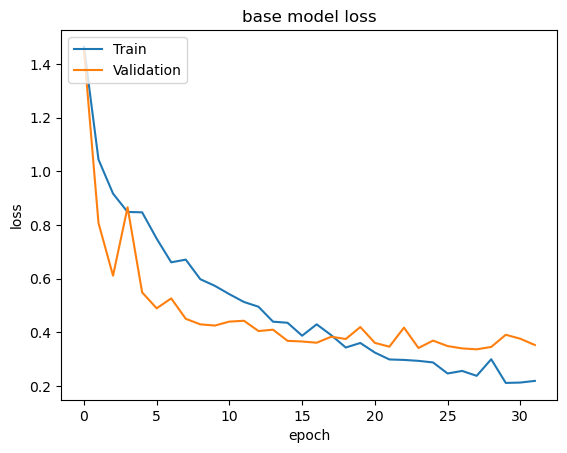

In [22]:
# plot and save graph of accuracy and loss
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('base model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.savefig('basemodel accuracy.png',dpi=150)
plt.show()
# summarize history for loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('base model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.savefig('basemodel loss.png',dpi=150)
plt.show()

In [23]:
y_pred = np.argmax(model_cnnbilstm.predict(x_test), axis = 1)

67/67 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step


### Confusion Matrix

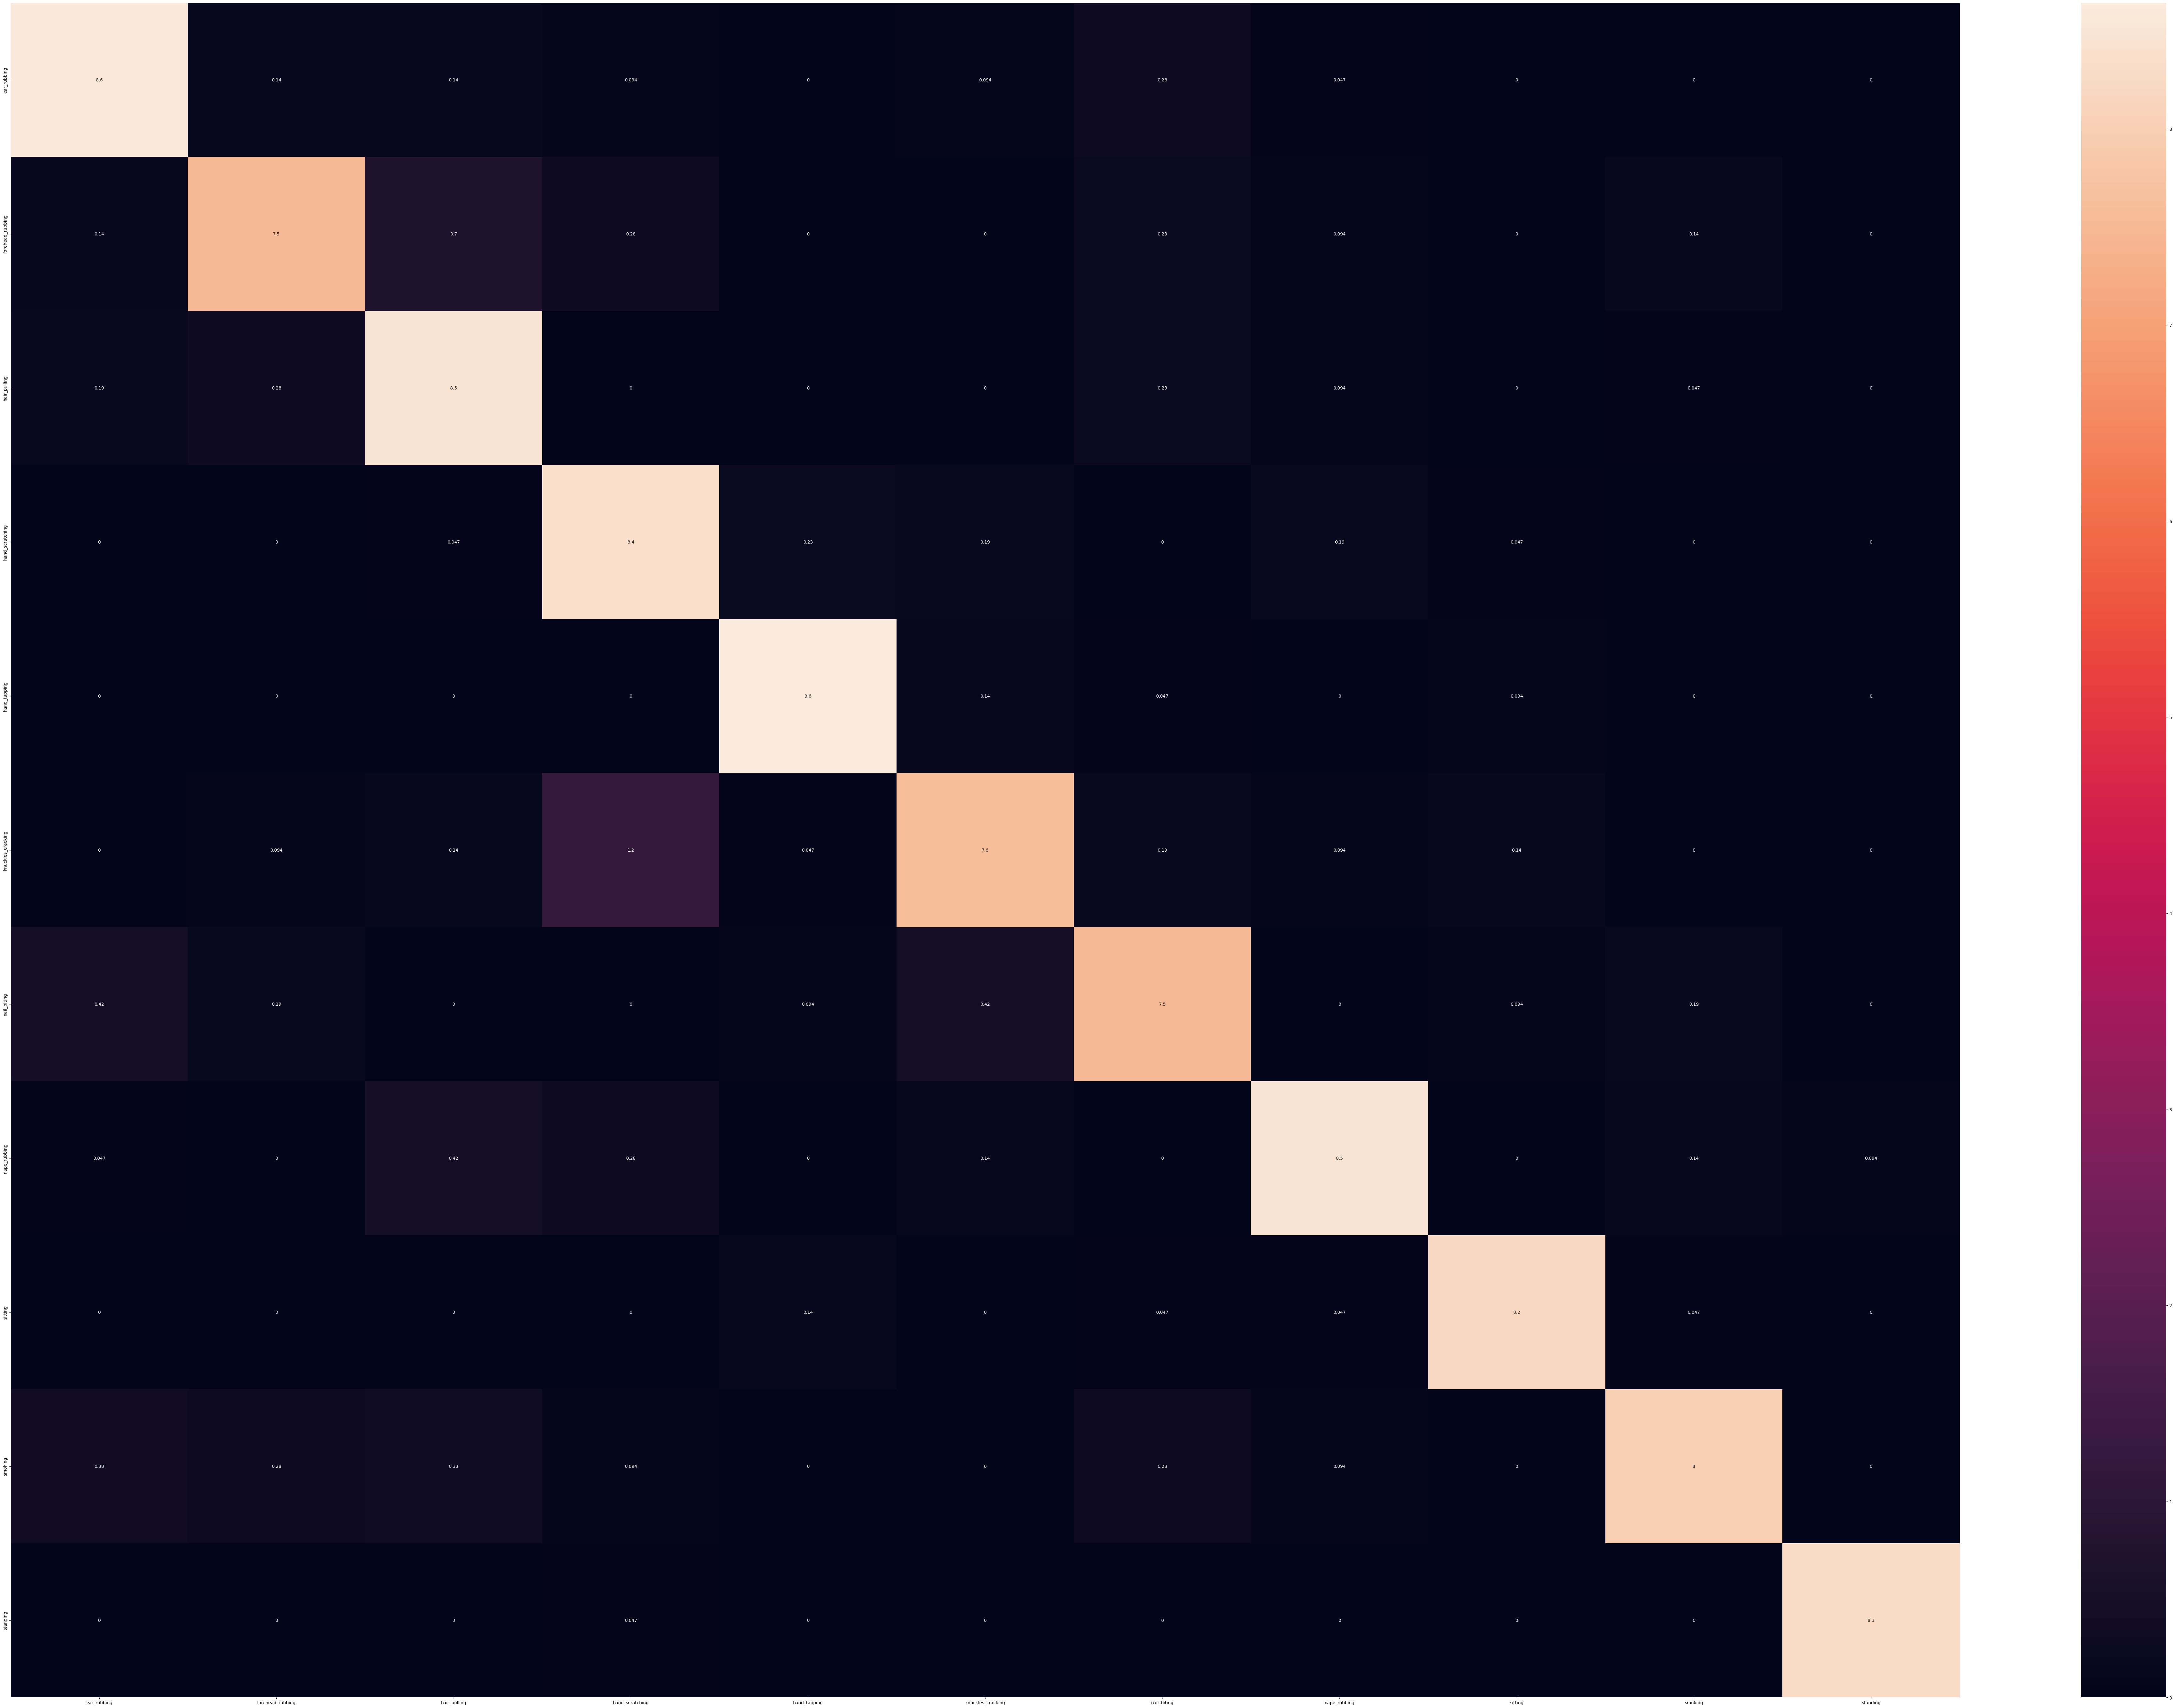

In [24]:
classes = label.classes_

# Build confusion matrix
cf_matrix = confusion_matrix(y_test, y_pred)
df_cm = pd.DataFrame(cf_matrix/np.sum(cf_matrix) *100, index = [i for i in classes],
                     columns = [i for i in classes])
plt.figure(figsize = (100,70))
sns.heatmap(df_cm, annot=True)
plt.savefig('confusionmatrix_cnnbilstm.png')

(<Figure size 700x700 with 1 Axes>,
 <Axes: xlabel='predicted label', ylabel='true label'>)

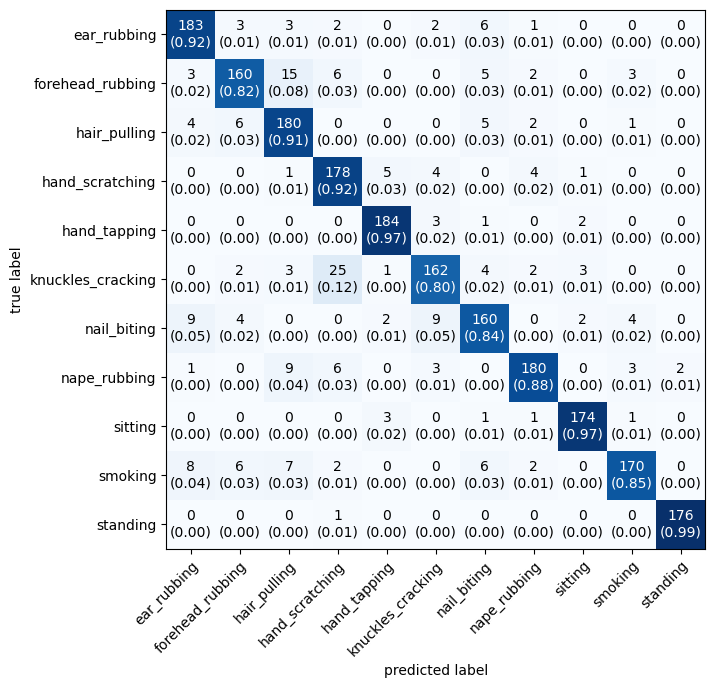

In [25]:
cmat = confusion_matrix(y_test, y_pred)
plot_confusion_matrix(conf_mat=cmat, class_names=label.classes_, show_normed=True, figsize=(7,7))

In [26]:
print(classification_report(y_test,y_pred, target_names=classes))

                   precision    recall  f1-score   support

      ear_rubbing       0.88      0.92      0.90       200
 forehead_rubbing       0.88      0.82      0.85       194
     hair_pulling       0.83      0.91      0.87       198
  hand_scratching       0.81      0.92      0.86       193
     hand_tapping       0.94      0.97      0.96       190
knuckles_cracking       0.89      0.80      0.84       202
      nail_biting       0.85      0.84      0.85       190
     nape_rubbing       0.93      0.88      0.90       204
          sitting       0.96      0.97      0.96       180
          smoking       0.93      0.85      0.89       201
         standing       0.99      0.99      0.99       177

         accuracy                           0.90      2129
        macro avg       0.90      0.90      0.90      2129
     weighted avg       0.90      0.90      0.90      2129



In [27]:
model_cnnbilstm.save("models/model_wrist_acc_gyro_cnnbilstm.keras")

In [28]:
report = classification_report(y_test, y_pred, output_dict=True, target_names=classes)
df_classification_report = pd.DataFrame(report).transpose()
df_classification_report = df_classification_report.sort_values(by=['f1-score'], ascending=False)
print(df_classification_report)
df_classification_report.to_csv('classification_report_cnnbilstm.csv')

                   precision    recall  f1-score      support
standing            0.988764  0.994350  0.991549   177.000000
sitting             0.956044  0.966667  0.961326   180.000000
hand_tapping        0.943590  0.968421  0.955844   190.000000
nape_rubbing        0.927835  0.882353  0.904523   204.000000
ear_rubbing         0.879808  0.915000  0.897059   200.000000
macro avg           0.898652  0.897524  0.896987  2129.000000
accuracy            0.895726  0.895726  0.895726     0.895726
weighted avg        0.897615  0.895726  0.895546  2129.000000
smoking             0.934066  0.845771  0.887728   201.000000
hair_pulling        0.825688  0.909091  0.865385   198.000000
hand_scratching     0.809091  0.922280  0.861985   193.000000
forehead_rubbing    0.883978  0.824742  0.853333   194.000000
nail_biting         0.851064  0.842105  0.846561   190.000000
knuckles_cracking   0.885246  0.801980  0.841558   202.000000


# New Data

In [9]:
#use
def load_and_classify(file_path, model_path, window_size, slide_size):
    """
    Loads new data from a CSV file, preprocesses it, and classifies it using the trained CNN model.
    
    Inputs:
    file_path (str): The path to the CSV file containing the new data.
    model (keras.Model): The trained CNN model.
    window_size (int): The size of the window to use for classification.
    slide_size (int): The amount to slide the window by.

    
    Returns:
    Result_df (pandas.DataFrame): A DataFrame containing the predicted activity labels for each window of the input data.
    """
    # Load the new data and model
    new_df = pd.read_csv(file_path)
    new_df = rename_columns_to_wrist(new_df,['merged_timestamp'])
    model = load_model(model_path)
    label_classes = ['ear_rubbing', 'forehead_rubbing', 'hair_pulling', 'hand_scratching', 'hand_tapping', 'knuckles_cracking', 'nail_biting', 'nape_rubbing', 'sitting', 'smoking', 'standing']
    columns = ["Ax_w", "Ay_w", "Az_w", "Gx_w", "Gy_w", "Gz_w"] 
    
    # Extract only wrist data columns (acc and gyro) like in the training data
    new_df_acc_gyro = new_df[columns]
    timestamps = new_df['timestamp'].values
    
    # Standardize the data using the same scaler
    scaler = StandardScaler()
    scaler.fit(new_df_acc_gyro)
    new_df_scaled = pd.DataFrame(scaler.transform(new_df_acc_gyro), columns=columns)
    
    # Add a dummy label column (required for get_window function)
    new_df_scaled['label'] = 0
    new_df_scaled['timestamp'] = timestamps
    
    # Get windows using the same function used for training data
    windows, _, start_indices = get_window(new_df_scaled, window_size, slide_size)
    
    # Reshape windows to match the model's input shape
    windows = windows.reshape(windows.shape[0], window_size, 6, 1)
    
    # Get predictions for each window
    predictions = model.predict(windows)
    predicted_labels = np.argmax(predictions, axis=1)
    
    label_encoder = LabelEncoder()
    label_encoder.fit(label_classes)
    # Convert numeric labels back to activity names
    predicted_activities = label_encoder.inverse_transform(predicted_labels)
    
    start_indices = np.array(start_indices)
    
    # Compute start and end timestamps
    start_time_ms = new_df_scaled['timestamp'].iloc[start_indices].values
    end_time_ms = new_df_scaled['timestamp'].iloc[(start_indices + window_size - 1)].values

    # Final DataFrame
    results_df = pd.DataFrame({
        'start_index': start_indices,
        'end_index': start_indices + window_size - 1,
        'start_time_ms': start_time_ms,
        'end_time_ms': end_time_ms,
        'predicted_activity': predicted_activities
    })
    
    return results_df

In [3]:
def get_window(df, window_size, slide_size):
    '''
    Creates sliding windows from the dataset.

    Parameters:
    df: pandas.DataFrame
    window_size: int, size of each window
    slide_size: int, step size for sliding window

    Returns:
    windows: np.array of shape (num_windows, window_size, 6)
    labels: np.array of majority labels per window
    start_indices: list of start indices for each window
    '''
    import numpy as np
    from scipy import stats

    N_features = 6
    windows = []
    labels = []
    start_indices = []

    for i in range(0, len(df) - window_size, slide_size):
        Ax_w = df['Ax_w'].values[i: i + window_size]
        Ay_w = df['Ay_w'].values[i: i + window_size]
        Az_w = df['Az_w'].values[i: i + window_size]
        Gx_w = df['Gx_w'].values[i: i + window_size]
        Gy_w = df['Gy_w'].values[i: i + window_size]
        Gz_w = df['Gz_w'].values[i: i + window_size]
        
        label = stats.mode(df['label'][i:i + window_size], keepdims=True)[0][0]

        windows.append([Ax_w, Ay_w, Az_w, Gx_w, Gy_w, Gz_w])
        labels.append(label)
        start_indices.append(i)

    windows = np.asarray(windows).reshape(-1, window_size, N_features)
    labels = np.asarray(labels)

    return windows, labels, start_indices


In [4]:
#file_path = 'anxiety_dataset.csv'
model_path = 'models/model_wrist_acc_gyro_cnnbilstm.keras'

In [5]:
#window frame
window_size = 200 #4 seconds
slide_size = 100 #50 percent overlap

In [29]:
result = load_and_classify('anxietycollected50hz.csv', model_path, window_size, slide_size)

23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step


## View results

In [30]:
result #predicted activities

,start_index,end_index,start_time_ms,end_time_ms,predicted_activity
0,0,199,2005-05-08 09:10:29.020,2005-05-08 09:10:33.000,sitting
1,100,299,2005-05-08 09:10:31.020,2005-05-08 09:10:35.000,sitting
2,200,399,2005-05-08 09:10:33.020,2005-05-08 09:10:37.000,hand_tapping
3,300,499,2005-05-08 09:10:35.020,2005-05-08 09:10:39.000,smoking
4,400,599,2005-05-08 09:10:37.020,2005-05-08 09:10:41.000,knuckles_cracking
...,...,...,...,...,...
720,72000,72199,2005-05-08 09:34:34.180,2005-05-08 09:34:38.180,standing
721,72100,72299,2005-05-08 09:34:36.180,2005-05-08 09:34:40.180,standing
722,72200,72399,2005-05-08 09:34:38.200,2005-05-08 09:34:42.180,nape_rubbing
723,72300,72499,2005-05-08 09:34:40.200,2005-05-08 09:34:44.180,standing


In [12]:
result.to_csv('predicted/predicted_1dcnnbilstm.csv', index=False)

In [24]:
from datetime import datetime

# Define activity intervals in datetime format
activity_ranges = [
    ("09:10:35", "09:12:36", "ear_rubbing"),
    ("09:12:41", "09:14:45", "forehead_rubbing"),
    ("09:14:50", "09:16:53", "hair_pulling"),
    ("09:17:02", "09:19:10", "hand_scratching"),
    ("09:19:18", "09:21:19", "hand_tapping"),
    ("09:21:31", "09:23:31", "knuckles_cracking"),
    ("09:23:36", "09:25:35", "nail_biting"),
    ("09:25:40", "09:27:43", "nape_rubbing"),
    ("09:27:55", "09:29:48", "sitting"),
    ("09:29:55", "09:32:38", "smoking"),
    ("09:32:54", "09:34:32", "standing"),
]

# Convert time strings to datetime.time
activity_ranges = [
    (datetime.strptime(start, "%H:%M:%S").time(),
     datetime.strptime(end, "%H:%M:%S").time(),
     label)
    for start, end, label in activity_ranges
]


In [33]:
# Ensure start_time_ms is datetime format
result['start_time'] = pd.to_datetime(result['start_time_ms'])
result['time_only'] = result['start_time'].dt.time

# Assign actual activity based on time ranges
def assign_actual_activity(time_value):
    for start_time, end_time, label in activity_ranges:
        if start_time <= time_value < end_time:
            return label
    return "unknown"

result['actual_activity'] = result['time_only'].apply(assign_actual_activity)


In [15]:
from sklearn.metrics import accuracy_score, confusion_matrix

In [32]:
label_classes = ['ear_rubbing', 'forehead_rubbing', 'hair_pulling', 'hand_scratching', 'hand_tapping',
                     'knuckles_cracking', 'nail_biting', 'nape_rubbing', 'sitting', 'smoking', 'standing']

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

Accuracy: 0.4866
Confusion Matrix:
                   ear_rubbing  forehead_rubbing  hair_pulling  \
ear_rubbing                 16                 0             6   
forehead_rubbing             9                39             5   
hair_pulling                 2                 0            51   
hand_scratching              1                 4            11   
hand_tapping                 0                 3             0   
knuckles_cracking            1                 0             6   
nail_biting                 33                 0             1   
nape_rubbing                 0                 0             0   
sitting                      0                 0             0   
smoking                      1                20             1   
standing                     0                 0             0   

                   hand_scratching  hand_tapping  knuckles_cracking  \
ear_rubbing                      9             0                 10   
forehead_rubbing              

In [ ]:

# Filter only valid activities for evaluation
mask_valid = result['actual_activity'] != 'unknown'
y_true = result[mask_valid]['actual_activity']
y_pred = result[mask_valid]['predicted_activity']

# Accuracy
accuracy = accuracy_score(y_true, y_pred)
print(f"Accuracy: {accuracy:.4f}")

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred, labels=label_classes)
print("Confusion Matrix:")
print(pd.DataFrame(conf_matrix, index=label_classes, columns=label_classes))

# Classification Report (Precision, Recall, F1-score per class)
print("\nClassification Report:")
print(classification_report(y_true, y_pred, labels=label_classes, target_names=label_classes))


In [34]:
# Filter only valid activities for evaluation
mask_valid = result['actual_activity'] != 'unknown'
y_true = result[mask_valid]['actual_activity']
y_pred = result[mask_valid]['predicted_activity']
accuracy = accuracy_score(y_true, y_pred)
conf_matrix = confusion_matrix(y_true, y_pred, labels=label_classes)

print(f"Accuracy: {accuracy:.4f}")
print("Confusion Matrix:")
print(pd.DataFrame(conf_matrix, index=label_classes, columns=label_classes))

Accuracy: 0.4866
Confusion Matrix:
                   ear_rubbing  forehead_rubbing  hair_pulling  \
ear_rubbing                 16                 0             6   
forehead_rubbing             9                39             5   
hair_pulling                 2                 0            51   
hand_scratching              1                 4            11   
hand_tapping                 0                 3             0   
knuckles_cracking            1                 0             6   
nail_biting                 33                 0             1   
nape_rubbing                 0                 0             0   
sitting                      0                 0             0   
smoking                      1                20             1   
standing                     0                 0             0   

                   hand_scratching  hand_tapping  knuckles_cracking  \
ear_rubbing                      9             0                 10   
forehead_rubbing              

<Axes: xlabel='predicted_activity', ylabel='count'>

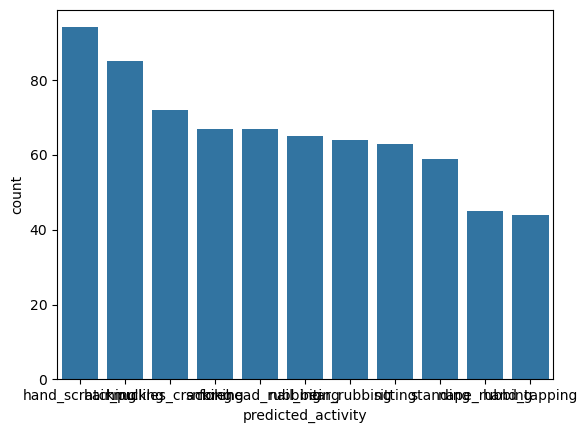

In [35]:
sns.countplot(x='predicted_activity', data = result, order=result.predicted_activity.value_counts().index)

In [36]:
result['predicted_activity'].value_counts()

predicted_activity
hand_scratching      94
hair_pulling         85
knuckles_cracking    72
smoking              67
forehead_rubbing     67
nail_biting          65
ear_rubbing          64
sitting              63
standing             59
nape_rubbing         45
hand_tapping         44
Name: count, dtype: int64